# PM2.5 forecasting - Extra Trees

Team: Amrane Mohamed, Bensaidane Nazim Adem, Tassadit Mohamed Amine, Benabdi Adem.

**First milestone: 14 November 2026.** This notebook runs and explains the real-data exploration and preprocessing. Extra Trees is the assigned model. Its factory is implemented, but real-data model training belongs to the December milestone.

The nearest-coordinate rule follows assignment section 5.3.4. Primary spatial CV groups physical stations. Historical target features require complete intervening daily history. All future-test dates remain reserved.

In [9]:
from pathlib import Path
import os, sys, json
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
assert (root / 'src' / 'run.py').exists(), 'Open this notebook from the pm25_project folder.'
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
try:
    try:
        import pandas as pd
    except ModuleNotFoundError:
        import subprocess
        subprocess.check_call([sys.executable, "-m", "pip", "install", "pandas"])
        import pandas as pd
except ModuleNotFoundError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pandas"])
    # pandas is already imported (or installed and imported) in the try/except above.
from IPython.display import display, Image  # pyright: ignore[reportMissingModuleSource]
config = json.loads((root / 'config/project.json').read_text())
out = root / 'results' / config['group']
config

{'seed': 42,
 'group': 'G6_ExtraTrees',
 'submission_group_code': None,
 'model': 'ExtraTreesRegressor',
 'model_group': 'G6',
 'dataset': 'sarahameziane/air-quality-mediterranean-basin-20162026',
 'dataset_version': 1,
 'dataset_archive_sha256': 'bd7a65c975cee1a833ff58a094b48a5a0806488b549ef0510210e8d694fa654b',
 'test_start': '2025-01-01',
 'spatial_threshold_degrees': 0.25,
 'n_splits': 5,
 'temporal_gap_days': 1,
 'target_min_exclusive': 0,
 'target_max_exclusive': 500,
 'forecast_horizon_days': 1,
 'spatial_grouping': 'station_id',
 'strict_contiguous_target_lags': True}

## 1. Reproduce the complete first milestone

This downloads dataset version 1 if needed, reconstructs joins, generates development-only EDA, creates causal features, freezes folds, verifies preprocessing, and builds the English report. No GPU is required. The source archive is about 9 MB compressed.

In [10]:
try:
    import scipy
except ModuleNotFoundError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "scipy"])
    import scipy

try:
    import matplotlib
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib

if not hasattr(matplotlib, "get_data_path"):
    raise RuntimeError(
        "Matplotlib is not available in this environment. "
        "Restart the kernel after installing the project dependencies."
    )

try:
    import seaborn as sns
except ModuleNotFoundError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "seaborn"])
    import seaborn as sns

try:
    import statsmodels
except ModuleNotFoundError:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "statsmodels"])
    import statsmodels

try:
    import sklearn
except ModuleNotFoundError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "scikit-learn"])
    import sklearn

import subprocess
import sys

def ensure_module(module_name, pip_name=None):
    pip_name = pip_name or module_name
    try:
        __import__(module_name)
    except Exception:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade", pip_name])
        __import__(module_name)

ensure_module("numpy", "numpy")
ensure_module("scipy", "scipy")
ensure_module("matplotlib", "matplotlib")
ensure_module("seaborn", "seaborn")
ensure_module("statsmodels", "statsmodels")
ensure_module("sklearn", "scikit-learn")

import matplotlib
import seaborn as sns
import statsmodels
import sklearn

from src.run import run
import subprocess
import matplotlib
run()


1/6 Source audit and causal feature construction
2/6 Development EDA and station-wise temporal diagnostics


c:\Users\amine\OneDrive\Desktop\PM25_Project_Phase1-final version\pm25_project\src\eda.py:95: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  test = adfuller(run.to_numpy(), autolag='AIC')
c:\Users\amine\OneDrive\Desktop\PM25_Project_Phase1-final version\pm25_project\src\eda.py:95: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  test = adfuller(run.to_numpy(), autolag='AIC')


3/6 Freeze temporal, station, grid and random partitions
4/6 Verify source alignment and fold-fitted preprocessing


PackageNotFoundError: No package metadata was found for reportlab

## 2. Audit sources before interpreting them

The raw PM2.5, GEE and supplied combined files have different populations. Missing targets and fixed invalid ranges are removed. A sensor label can occur at different coordinates; physical-site IDs distinguish them.

In [ ]:
display(pd.read_csv(out / 'source_inventory.csv'))
display(pd.read_csv(out / 'cleaning_counts.csv'))
audit = json.loads((out / 'audit.json').read_text())
audit['source_checks']

,file,rows,columns,exact_duplicates,date_min,date_max
0,pm25.csv,88041,5,0,2016-11-21,2026-04-16
1,gee_features_daily.csv,164208,13,0,2016-11-21,2026-04-06
2,combined_gee_pm25.csv,41718,15,0,2016-11-25,2026-04-06


,stage,count
0,missing_target,0
1,invalid_low,2093
2,invalid_high,19
3,valid_target_rows,85929
4,unmapped_valid_target_rows,8624
5,valid_mapped_target_rows,77305
6,missing_same_day_gee,30391
7,same_day_matched_rows,46914
8,forecast_rows,45383
9,development_rows,33282


{'provided_rows': 41718,
 'target_rows_found': 41718,
 'target_mismatches': 0,
 'predictor_mismatches': {'AOD': 0,
  'NO2': 0,
  'CO': 0,
  'O3': 0,
  'temperature_celsius': 0,
  'pressure_mb': 0,
  'wind_u': 0,
  'wind_v': 0},
 'datetime_utc_agrees_with_date': True,
 'provided_max_grid_distance_degrees': 0.0}

## 3. Check the station join

Each physical site maps once to its nearest GEE location within 0.25 degrees. The distance is angular, not kilometres. Missing GEE dates do not cause a station to jump to another location. The supplied combined file uses exact coordinates; the reconstructed population follows assignment section 5.3.4. A like-for-like exact-match audit records the difference.

,sites
accepted,
False,17
True,116


,sensor_name,latitude,longitude,station_id,id,distance_degrees,accepted
80,Malek,34.290390,8.762355,S080,90,4.958000,False
13,Algiers,36.755798,3.039114,S013,81,3.928395,False
17,BASTIA GIRAUD,42.697918,9.446417,S017,91,3.451315,False
18,BASTIA MONTESORO,42.671333,9.434639,S018,91,3.423792,False
37,CIUTADELLA DE MENORCA,40.010611,3.857583,S037,42,2.162558,False
46,ES1828A,40.009440,3.856480,S046,42,2.162490,False
85,NICE PROMENADE,43.689290,7.242074,S085,72,1.790570,False
126,balcon SE pas de vent,43.689182,7.219662,S126,72,1.768341,False
127,balcon SE à 150m,43.689014,7.219666,S127,72,1.768323,False
102,SSOO,35.273060,-2.940830,S102,95,1.643940,False


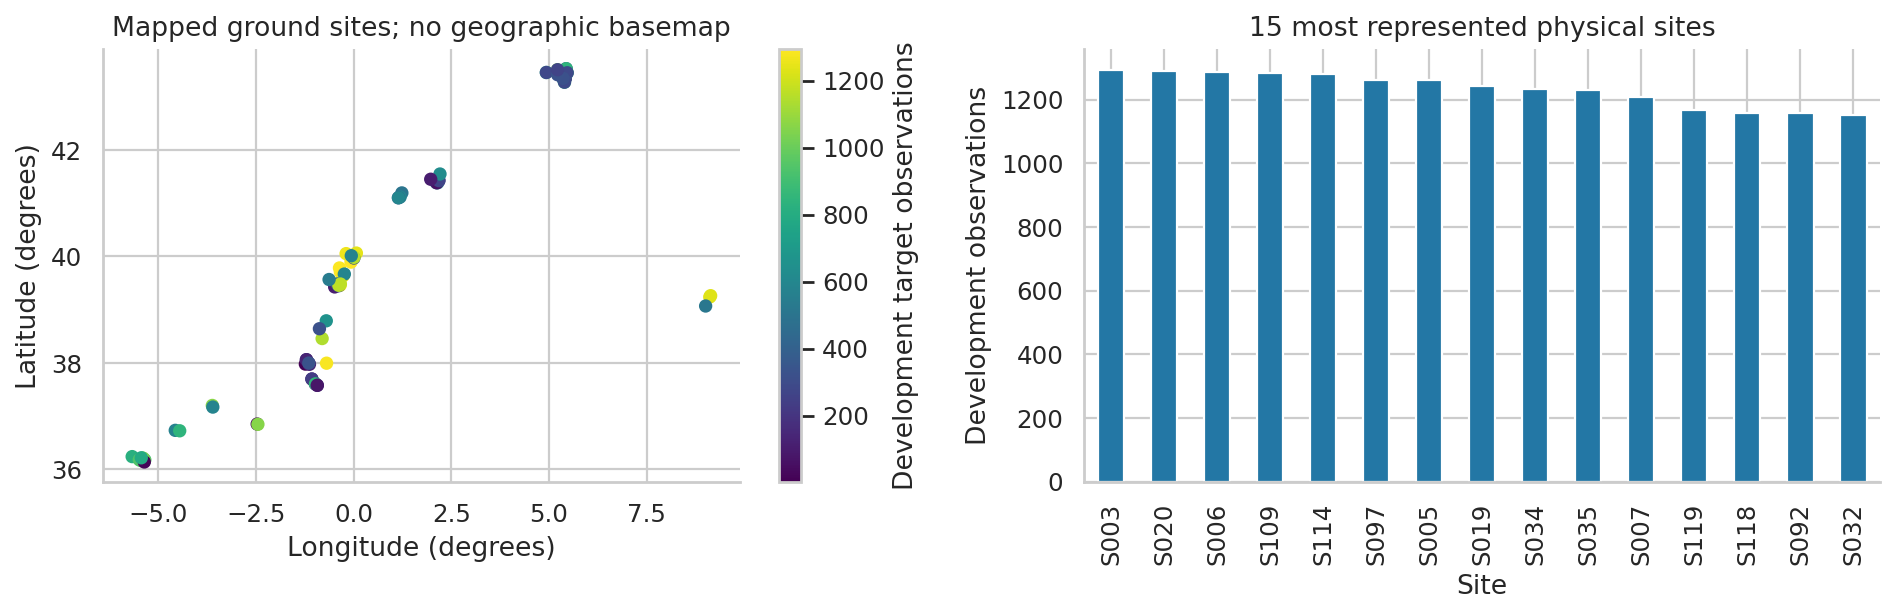

In [ ]:
mapping = pd.read_csv(out / 'station_mapping.csv')
display(mapping.groupby('accepted').agg(sites=('station_id', 'size')))
display(mapping.sort_values('distance_degrees', ascending=False).head(10))
display(Image(filename=str(out / 'figures/07_spatial_coverage.png')))

## 4. Describe the target and predictors

These summaries and plots use only valid same-day matched data before 2025. Numeric records include min/max, quartiles, mean/std, skewness and excess kurtosis. Cleaning records are separately typed in the same required CSV. Plausible pollution extremes are retained.

,variable,count,mean,std,min,q25,median,q75,max,skewness,excess_kurtosis,missing_count,missing_pct,scope,record_type
0,AOD,34832.0,0.151010,0.105150,0.000000,0.083000,0.130500,0.196000,5.475000,8.287875,290.356822,0.0,0.000000,development_same_day_matched,numeric_summary
1,NO2,32425.0,0.000092,0.000027,0.000027,0.000076,0.000087,0.000102,0.000483,2.156415,9.613826,2407.0,6.910312,development_same_day_matched,numeric_summary
2,CO,32425.0,0.031816,0.003763,0.013058,0.029306,0.031708,0.034158,0.060841,0.498335,2.164110,2407.0,6.910312,development_same_day_matched,numeric_summary
3,O3,32384.0,0.142952,0.014638,0.103899,0.133602,0.139954,0.149819,0.229322,1.305297,3.120390,2448.0,7.028020,development_same_day_matched,numeric_summary
4,temperature_celsius,34832.0,18.431734,6.217578,-0.569204,13.393755,18.805249,23.727209,34.865831,-0.171902,-0.899269,0.0,0.000000,development_same_day_matched,numeric_summary
5,pressure_mb,34832.0,993.651777,17.134112,933.022568,987.163556,997.478230,1005.278995,1033.662176,-1.012039,0.566990,0.0,0.000000,development_same_day_matched,numeric_summary
6,wind_u,34832.0,0.354438,2.578640,-11.098723,-0.984747,0.200203,1.736517,8.834192,-0.217241,0.960897,0.0,0.000000,development_same_day_matched,numeric_summary
7,wind_v,34832.0,-0.211629,1.444047,-10.860048,-0.741143,0.039628,0.667381,8.486383,-1.456717,4.307066,0.0,0.000000,development_same_day_matched,numeric_summary
8,pm25,34832.0,9.259877,10.033996,0.006667,4.526667,7.666667,11.923077,484.981500,18.898230,677.136950,0.0,0.000000,development_same_day_matched,numeric_summary


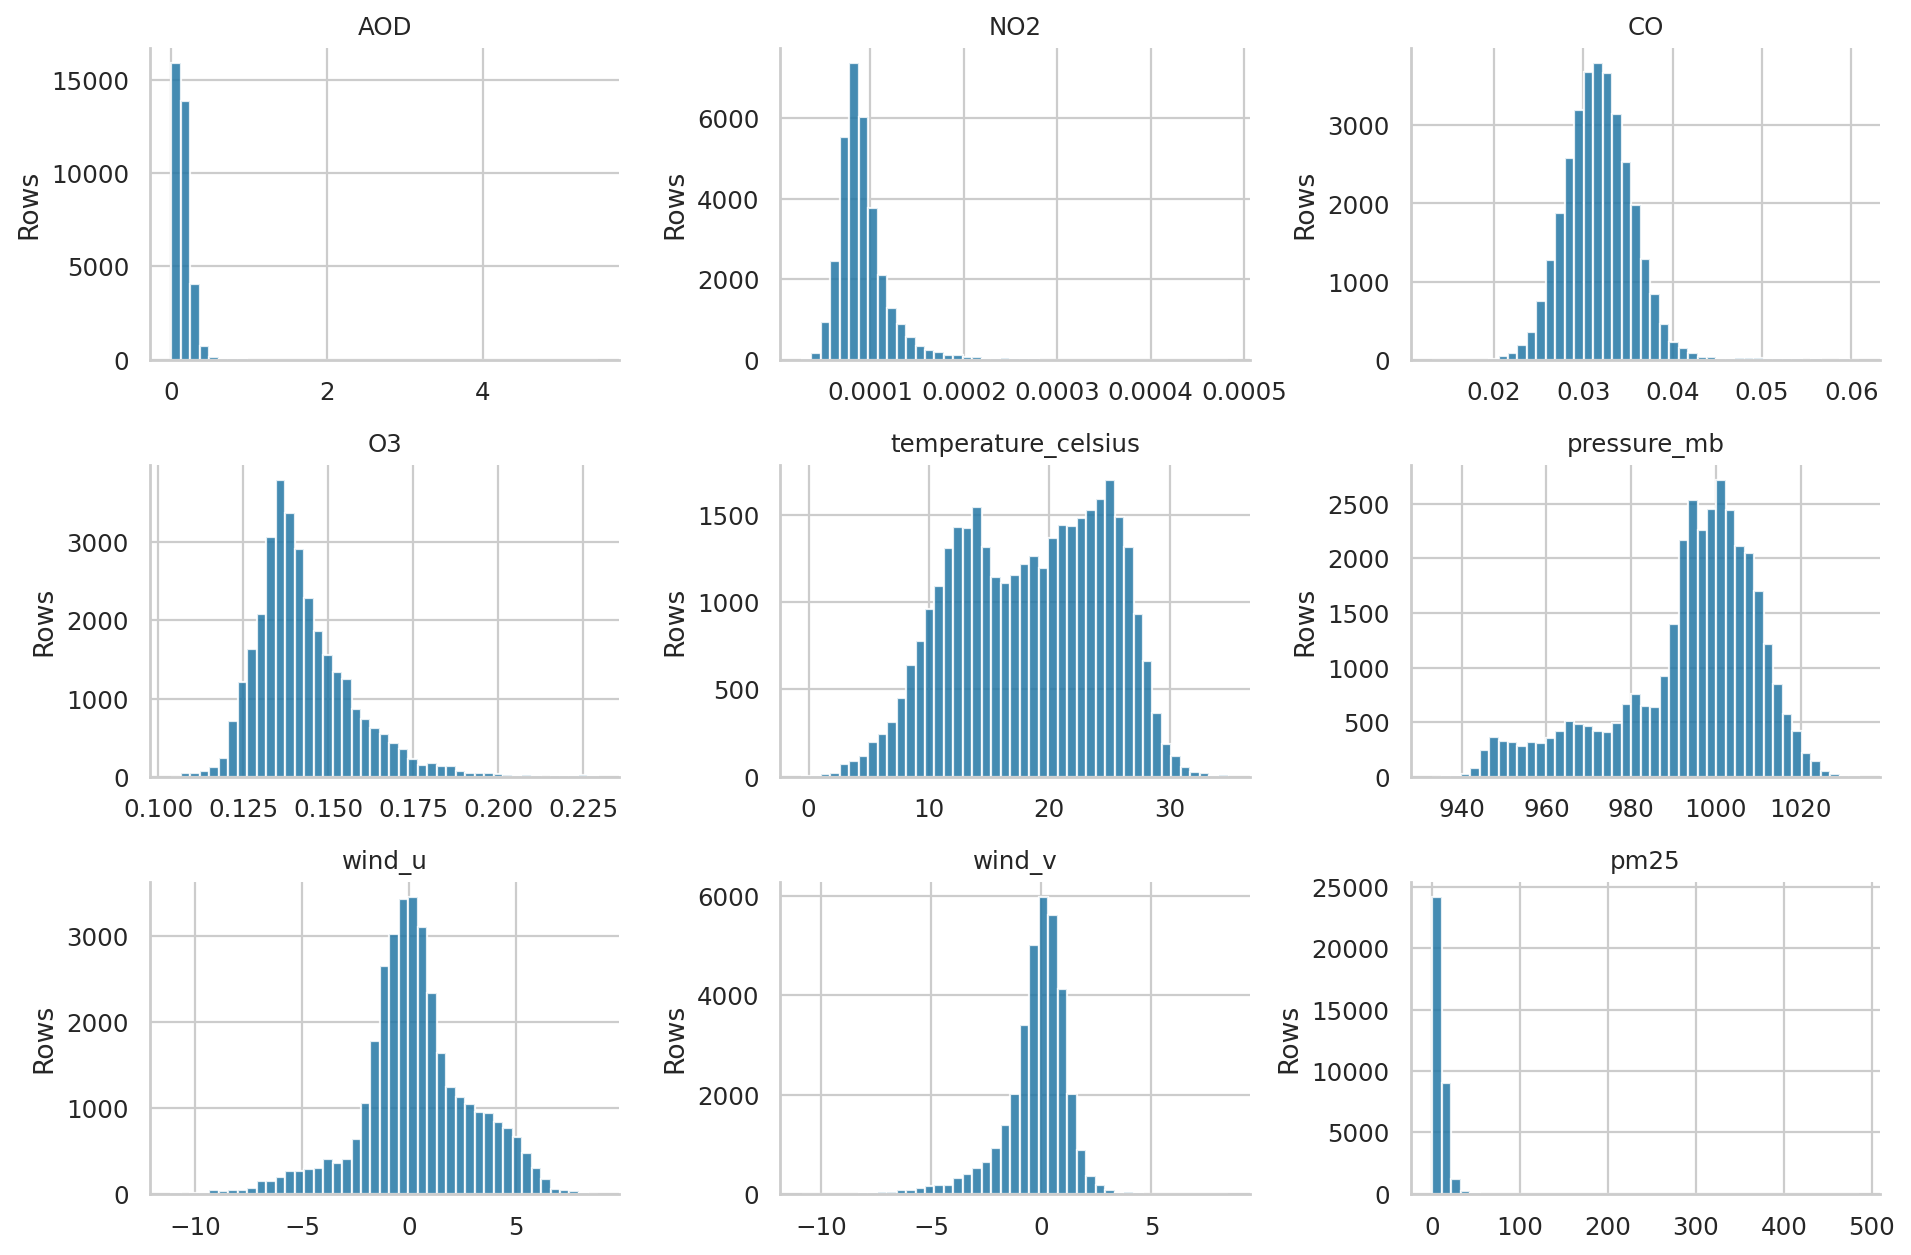

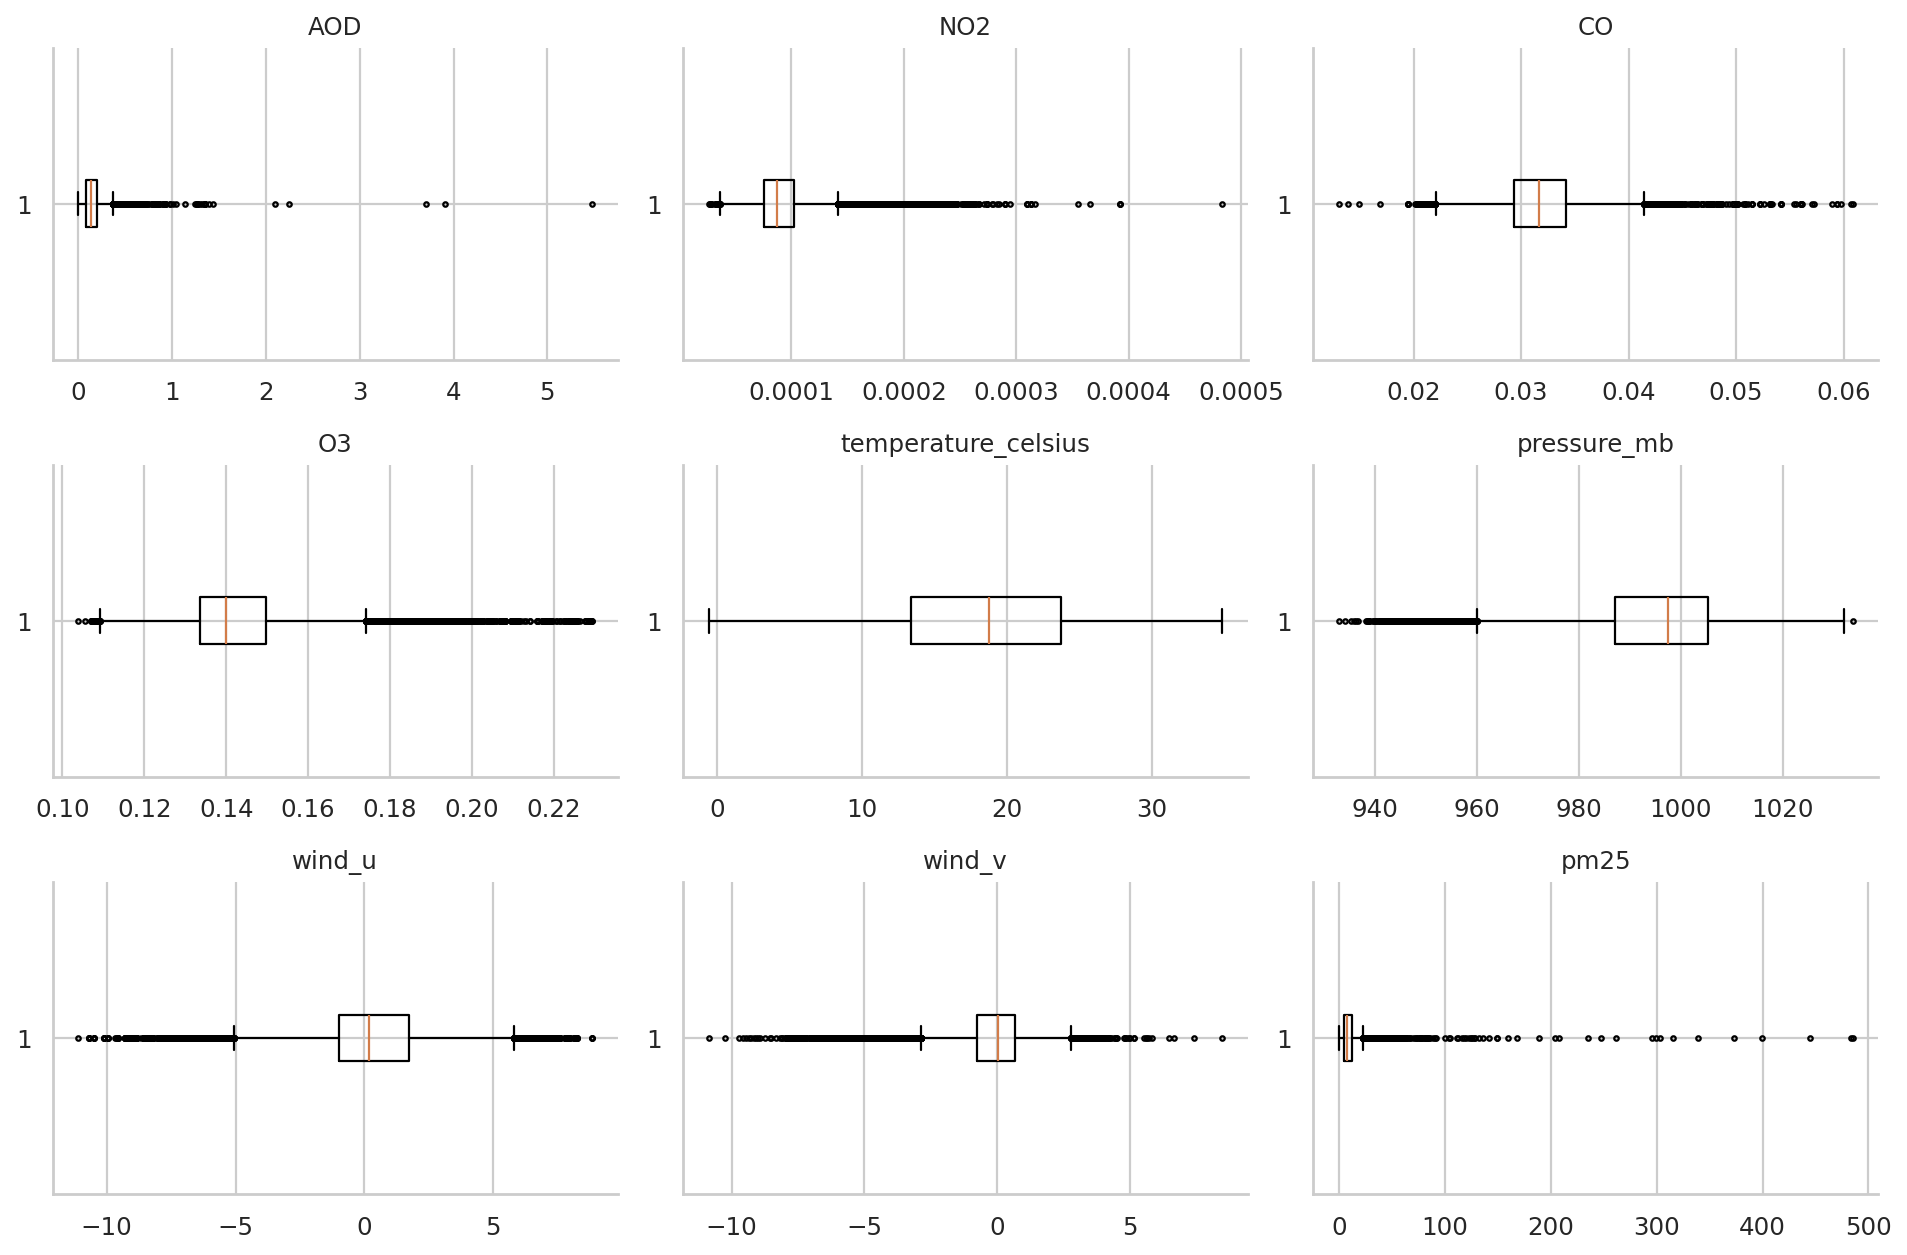

In [ ]:
summary = pd.read_csv(out / 'Exploratory_Data.csv')
display(summary[summary.record_type.eq('numeric_summary')])
display(Image(filename=str(out / 'figures/01_distributions.png')))
display(Image(filename=str(out / 'figures/02_boxplots.png')))

## 5. Missingness is a time-dependent property

Inspect the missingness of NO2/CO/O3 by month and station. A single average may hide early-period absence. Use a training-fold median and explicit gas missingness indicators. Do not forward-fill the gas columns across days or use future values for interpolation.

,month,NO2,CO,O3
0,2016-11,100.000000,100.000000,100.0
1,2016-12,100.000000,100.000000,100.0
2,2017-01,100.000000,100.000000,100.0
3,2017-02,100.000000,100.000000,100.0
4,2017-03,100.000000,100.000000,100.0
5,2017-04,100.000000,100.000000,100.0
6,2017-05,100.000000,100.000000,100.0
7,2017-06,100.000000,100.000000,100.0
8,2017-07,100.000000,100.000000,100.0
9,2017-09,100.000000,100.000000,100.0


,station_id,NO2,CO,O3
0,S001,0.000000,0.000000,0.000000
1,S003,19.924812,19.924812,20.050125
2,S004,0.000000,0.000000,0.000000
3,S005,20.367937,20.367937,20.762155
4,S006,20.752270,20.752270,21.011673


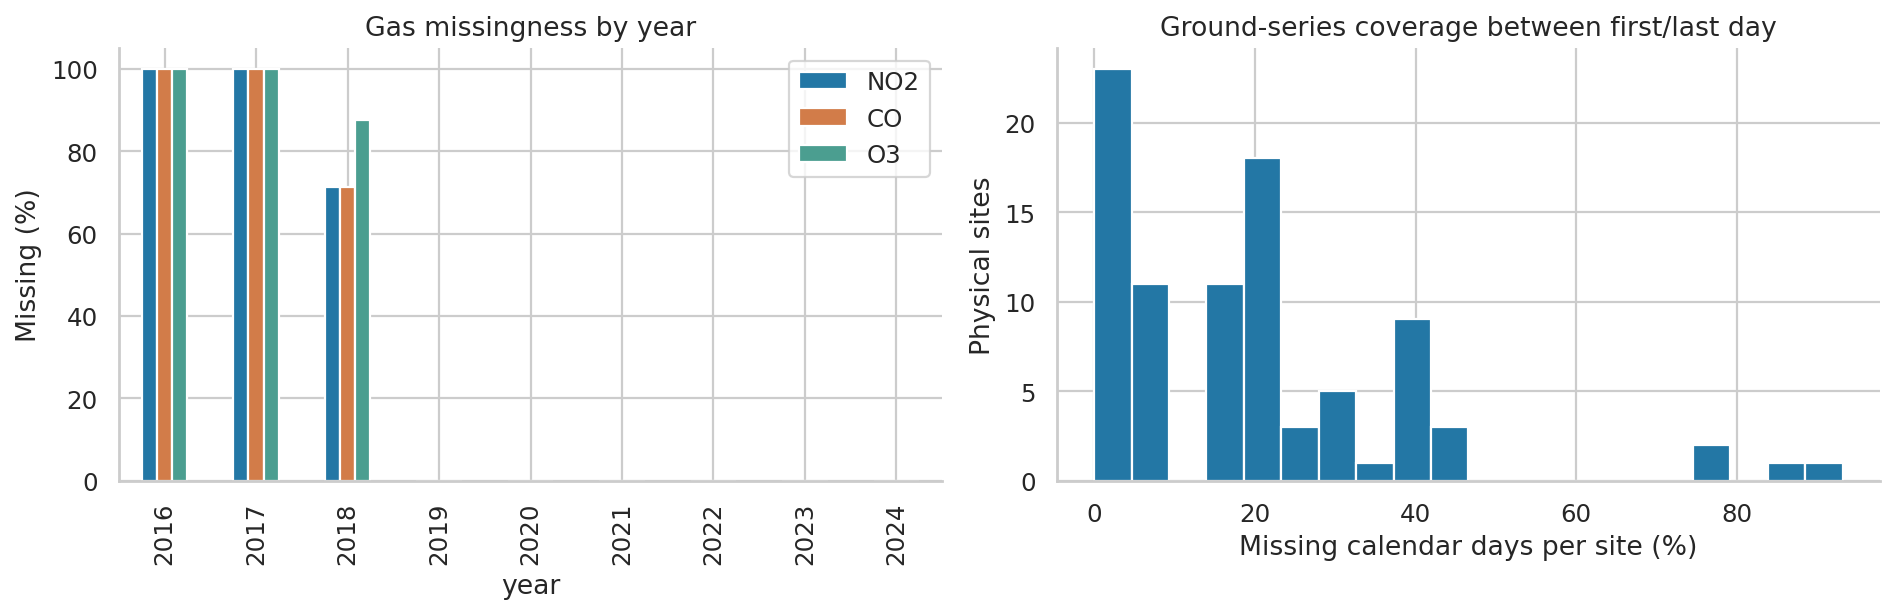

In [ ]:
display(pd.read_csv(out / 'gas_missingness_by_month.csv').head(24))
display(pd.read_csv(out / 'gas_missingness_by_station.csv').head())
display(Image(filename=str(out / 'figures/05_missingness.png')))

## 6. Verify daily regularity before making lags

Daily histories are reindexed separately for each physical site. Missing days remain missing. ACF uses exact calendar lags; ADF, PACF and Ljung-Box use contiguous segments, avoiding artificial adjacency across gaps. A weekly seasonal model is a hypothesis to verify, not a default assumption.

## Seasonal and weather-dependent AOD relationships

These development-only descriptive coefficients do not establish causality or model accuracy.

In [ ]:
conditional = pd.read_csv(out / 'aod_conditional_associations.csv')
display(conditional[conditional.stratification.ne('station')])
display(pd.read_csv(out / 'annual_drift.csv'))
display(pd.read_csv(out / 'preprocessing_fold_checks.csv'))

,stratification,group,rows,spearman
0,season,DJF,6907,0.235103
1,season,JJA,11364,0.154537
2,season,MAM,7513,0.176865
3,season,SON,9048,0.199581
92,temperature_celsius,"(-0.57, 13.394]",8708,0.179597
93,temperature_celsius,"(13.394, 18.805]",8708,0.145471
94,temperature_celsius,"(18.805, 23.727]",8708,0.160872
95,temperature_celsius,"(23.727, 34.866]",8708,0.136085
96,wind_speed,"(0.0093, 0.994]",8708,0.095701
97,wind_speed,"(0.994, 1.688]",8709,0.044538


,year,count,median,q25,q75,above25_pct,above50_pct
0,2016,111,10.166667,6.944444,14.000000,1.801802,0.000000
1,2017,2116,7.666667,4.643189,11.939967,3.827977,0.330813
2,2018,252,7.018750,4.440476,10.611979,0.396825,0.000000
3,2019,1772,6.718254,3.000000,12.387440,4.288939,0.056433
4,2020,3251,5.714286,3.238247,9.800000,2.122424,0.092279
5,2021,4938,7.000000,3.857143,11.444444,2.855407,0.607533
6,2022,5117,8.190000,4.810000,12.180000,2.051984,0.449482
7,2023,6022,8.814239,5.475833,13.000000,2.308203,0.182664
8,2024,11253,7.783784,4.927500,11.708333,2.897005,0.186617


,fold,train_rows,validation_rows,transformed_columns,all_finite,empty_training_features,scaling
0,1,2121,1604,22,True,NO2_lag1;CO_lag1;O3_lag1,disabled for Extra Trees
1,2,3719,3031,22,True,NaN,disabled for Extra Trees
2,3,6756,6784,22,True,NaN,disabled for Extra Trees
3,4,13530,5703,22,True,NaN,disabled for Extra Trees
4,5,19237,14039,22,True,NaN,disabled for Extra Trees


,station_id,sensor_name,observations,first_date,last_date,span_days,missing_days,missing_day_pct,consecutive_pair_pct,longest_contiguous_days,acf_lag1_calendar,acf_lag7_calendar,adf_statistic,adf_pvalue,adf_lags,ljung_box_lag,ljung_box_pvalue,diagnostic_status,scope
0,S090,Perafort,504,2023-03-30,2024-12-31,643,139,21.617418,98.210736,286,0.605128,0.230883,-8.640190,5.452492e-14,0.0,7.0,1.602074e-24,NaN,development_mapped_ground_history
1,S084,Mollet del Vallès,626,2023-03-30,2024-12-31,643,17,2.643857,98.720000,274,0.700893,0.288764,-6.371551,2.338332e-08,0.0,7.0,2.069051e-88,NaN,development_mapped_ground_history
2,S010,AMU_St Jerome_road,251,2024-04-24,2024-12-31,252,1,0.396825,99.600000,250,0.727297,0.074571,-3.890233,2.107911e-03,2.0,7.0,6.433388e-41,NaN,development_mapped_ground_history
3,S011,AMU_St Jerome_roof,248,2024-04-24,2024-12-28,249,1,0.401606,99.595142,247,0.661919,0.152478,-5.755129,5.843700e-07,2.0,7.0,7.340251e-38,NaN,development_mapped_ground_history
4,S009,AMU_St Jerome_building,238,2024-04-24,2024-12-18,239,1,0.418410,99.578059,237,0.672591,0.161216,-3.990533,1.460901e-03,5.0,7.0,3.751645e-43,NaN,development_mapped_ground_history
5,S021,Barcelona,590,2023-05-07,2024-12-31,605,15,2.479339,98.471986,212,0.598626,0.073105,-7.073634,4.864844e-10,0.0,7.0,7.531710e-17,NaN,development_mapped_ground_history
6,S098,SAGUNT PORT,593,2023-05-05,2024-12-31,607,14,2.306425,98.986486,198,0.590971,0.053618,-3.418180,1.035450e-02,5.0,7.0,1.516178e-18,NaN,development_mapped_ground_history
7,S032,CASTELLÓ-GRAU,1150,2020-02-23,2024-08-09,1630,480,29.447853,93.211488,197,0.800970,0.548657,-5.084095,1.508898e-05,0.0,7.0,2.788357e-57,NaN,development_mapped_ground_history
8,S039,CORTIJILLOS,1045,2021-05-17,2024-12-31,1325,280,21.132075,89.080460,197,0.688417,0.320548,-3.961288,1.627348e-03,2.0,7.0,8.254060e-56,NaN,development_mapped_ground_history
9,S075,MEDITERRÁNEO,1057,2021-05-17,2024-12-31,1325,268,20.226415,88.636364,197,0.348937,-0.004724,-6.023938,1.471194e-07,0.0,7.0,1.093994e-26,NaN,development_mapped_ground_history


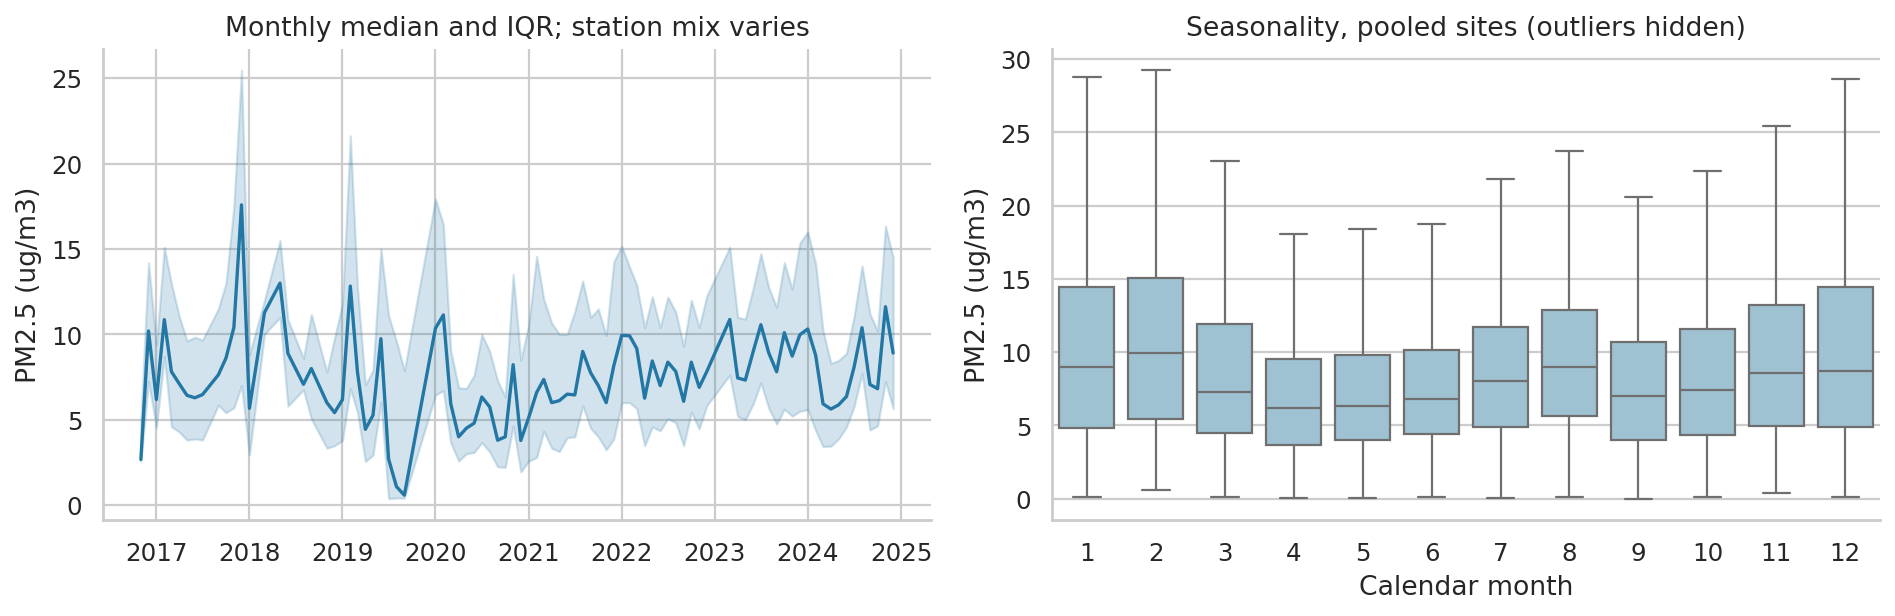

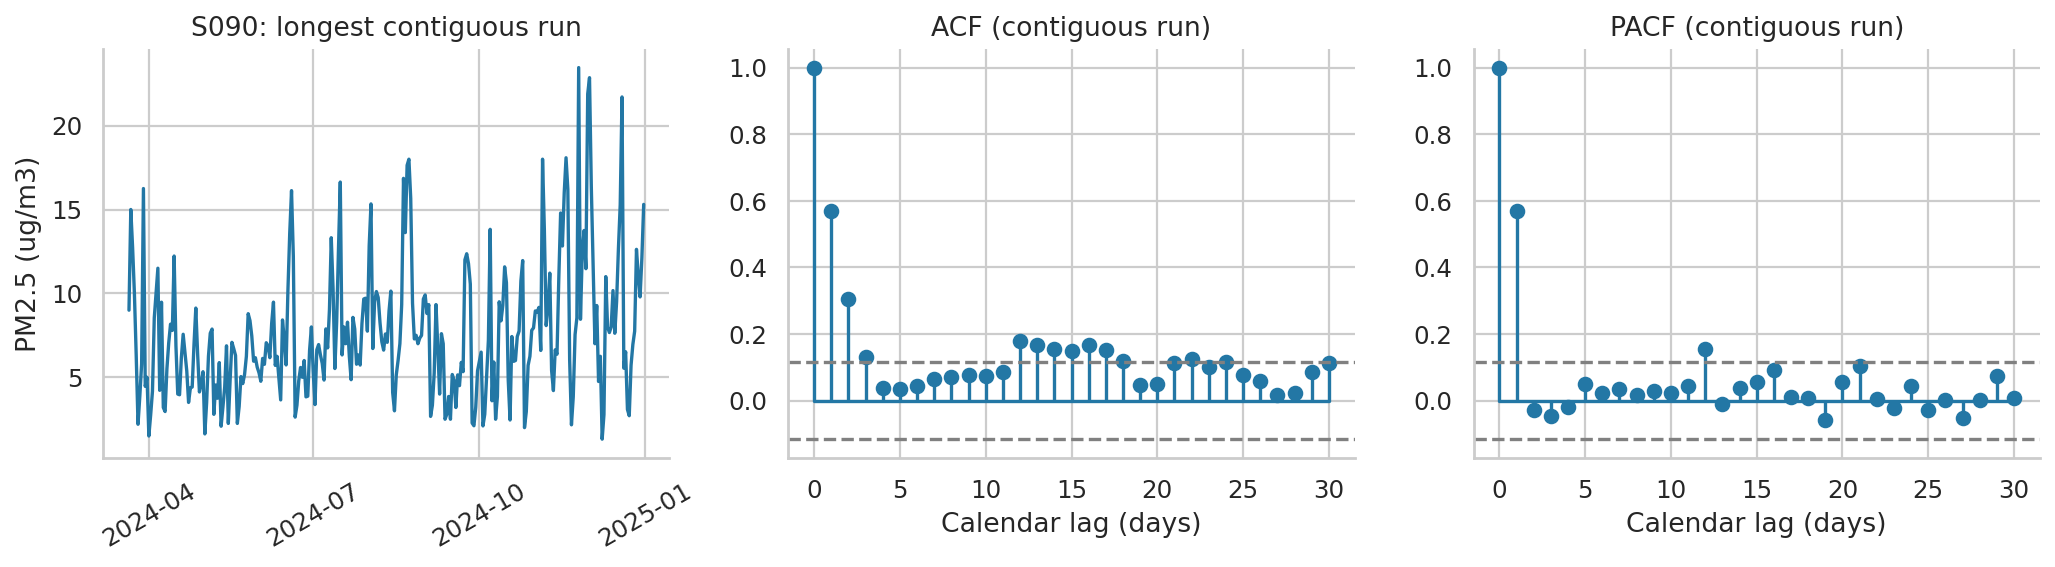

In [ ]:
temporal = pd.read_csv(out / 'Exploratory_temporal.csv')
display(temporal.head(10))
display(Image(filename=str(out / 'figures/03_temporal_patterns.png')))
display(Image(filename=str(out / 'figures/06_time_diagnostics.png')))

## 7. Associations are descriptive

Pearson and Spearman correlations, scatter-density plots, and station-wise lead-lag associations describe relationships. Seasonal effects and changing site composition can confound them. Negative-lag correlations inspect future variables for exploration only; those variables never enter the forecast feature manifest.

,method,feature_1,feature_2,correlation


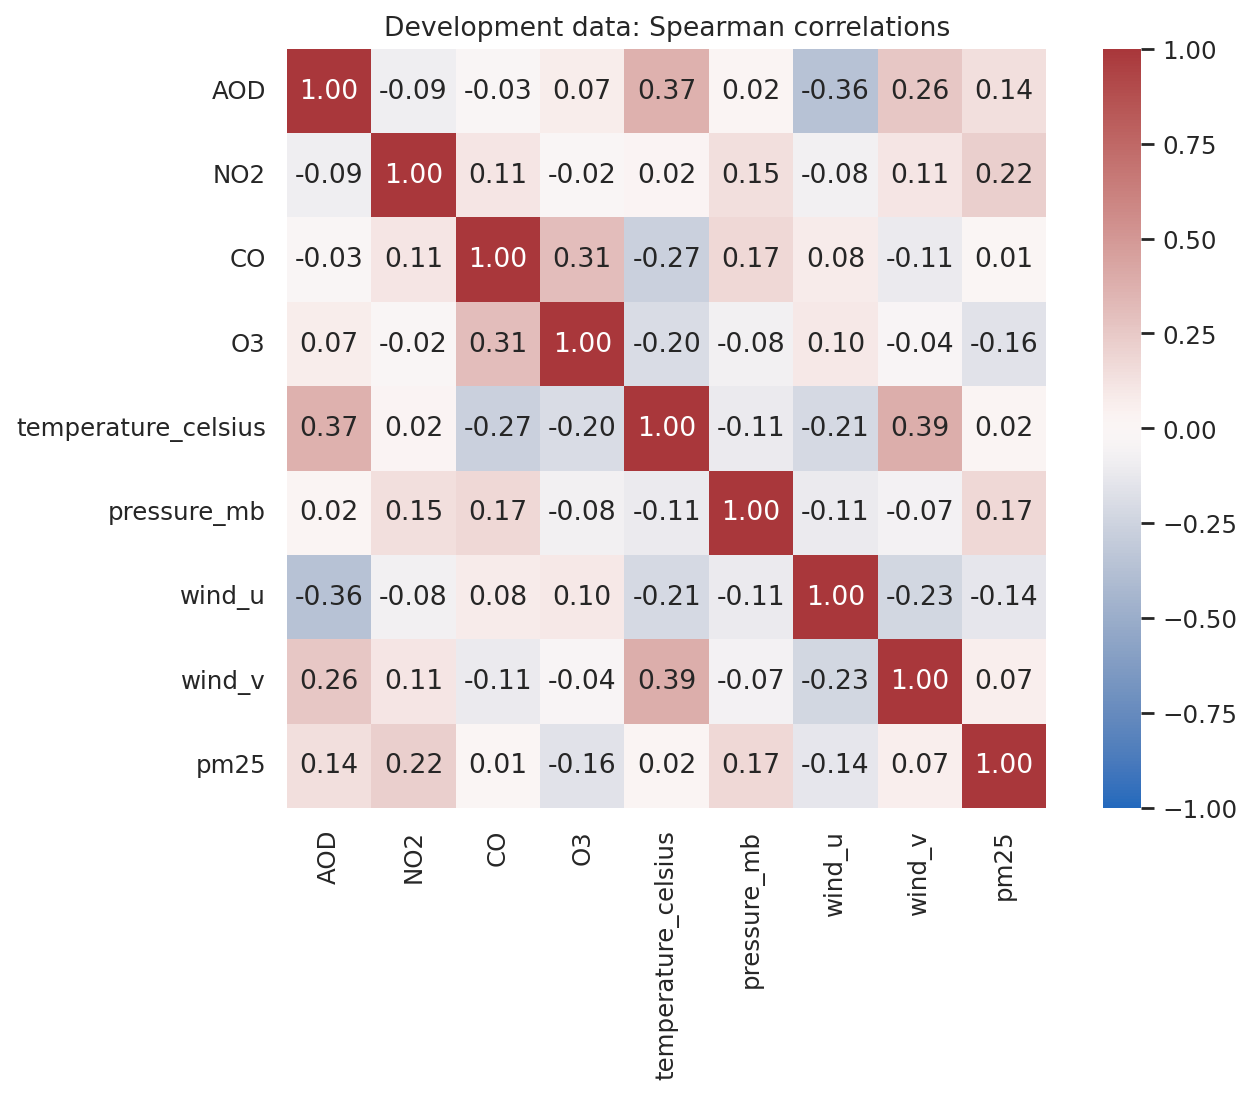

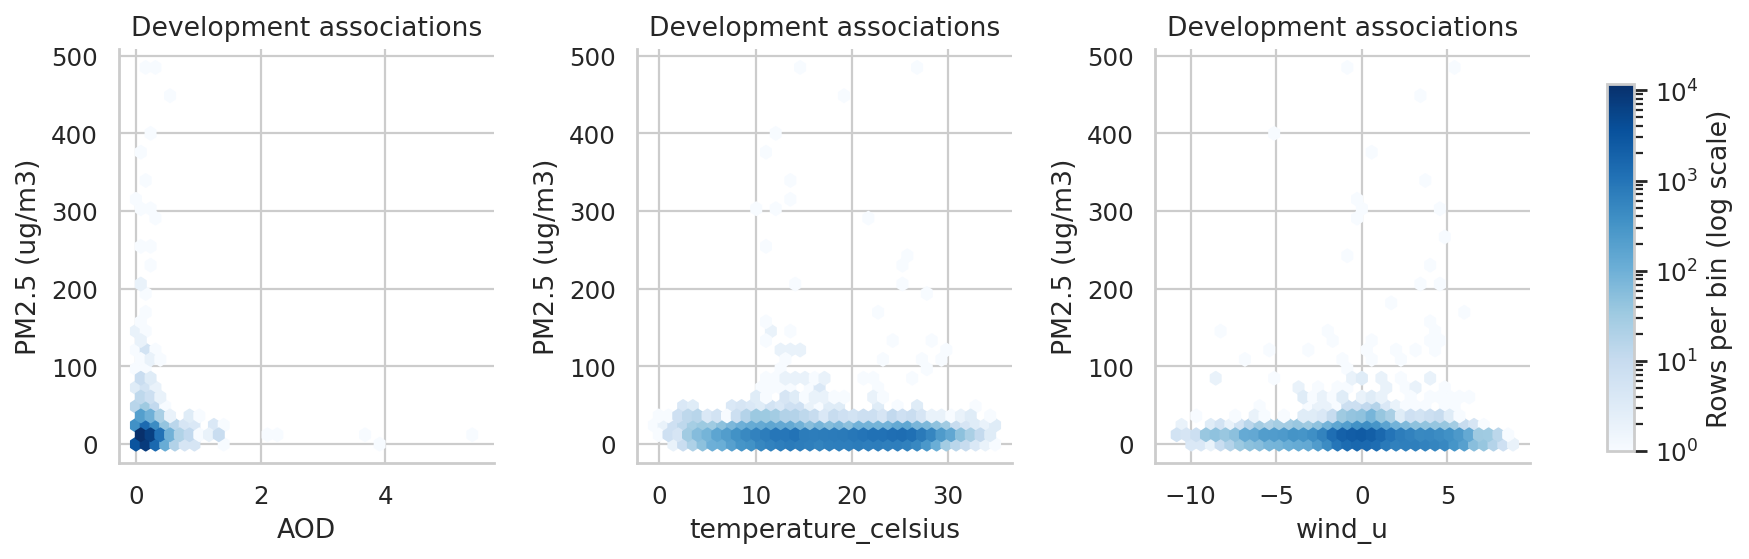

In [ ]:
display(pd.read_csv(out / 'high_correlations.csv'))
display(Image(filename=str(out / 'figures/04_correlations.png')))
display(Image(filename=str(out / 'figures/08_relationships.png')))

## 8. Define what is known at prediction time

To forecast day t, use GEE dated t-1, exact-date historical PM2.5, and calendar information for t. A lag k is missing if any of the preceding days 1 through k is absent. A 7-day rolling statistic requires all seven past calendar observations. Real satellite/reanalysis publication latency still needs verification.

The forecasting population differs from same-day EDA: only t-1 atmospheric availability matters for the causal table. An entirely unseen location without ground history needs a separate variant with all PM2.5-history features removed.

In [ ]:
from src.preprocessing import FEATURES, make_preprocessor
dev = pd.read_csv(root / 'data/processed/development_forecast.csv', parse_dates=['date', 'feature_date'])
assert ((dev.date - dev.feature_date).dt.days == 1).all()
display(dev[['row_id', 'station_id', 'date', 'feature_date', 'pm25', 'AOD_lag1', 'pm25_lag1', 'pm25_past7_mean']].head(12))
print('Development rows:', len(dev))
print('Predictor count before missingness indicators:', len(FEATURES))

Development rows: 33282
Predictor count before missingness indicators: 19


,row_id,station_id,date,feature_date,pm25,AOD_lag1,pm25_lag1,pm25_past7_mean
0,0,S086,2016-11-26,2016-11-25,13.5,0.111000,2.750000,NaN
1,1,S019,2016-11-28,2016-11-27,3.0,0.039000,NaN,NaN
2,2,S005,2016-12-01,2016-11-30,5.0,0.238000,2.400000,NaN
3,3,S019,2016-12-01,2016-11-30,3.0,0.248000,2.600000,NaN
4,4,S003,2016-12-03,2016-12-02,7.0,0.095500,6.200000,4.681633
5,5,S005,2016-12-03,2016-12-02,2.0,0.055000,5.333333,NaN
6,6,S006,2016-12-03,2016-12-02,14.0,0.095500,7.800000,6.355782
7,7,S007,2016-12-03,2016-12-02,12.0,0.074500,9.333333,NaN
8,8,S019,2016-12-03,2016-12-02,7.0,0.073667,4.000000,NaN
9,9,S020,2016-12-03,2016-12-02,7.0,0.113500,8.666667,NaN


## 9. Freeze development folds and protect the final period

All target dates from 2025 onward are reserved. The notebook never opens their label table. Temporal folds split calendar dates with a one-day gap, preventing stations from the same day from straddling boundaries. Primary spatial folds group physical station IDs. Extra grid-grouped folds keep shared GEE locations together. Shuffled folds are diagnostic only.

Fit transformations on training rows only. The following example demonstrates preprocessing; it is not a fitted forecasting model.

In [ ]:
display(pd.read_csv(out / 'fold_overview.csv'))
fold = json.loads((out / 'folds_temporal.json').read_text())[0]
by_id = dev.set_index('row_id')
train = by_id.loc[fold['train_row_ids']]
validation = by_id.loc[fold['validation_row_ids']]
preprocessor = make_preprocessor(scale=False)
X_train = preprocessor.fit_transform(train[FEATURES])
X_validation = preprocessor.transform(validation[FEATURES])
print(X_train.shape, X_validation.shape)
display(json.loads((out / 'validation_checks.json').read_text()))

(2121, 22) (1604, 22)


,scheme,fold,train_rows,validation_rows,train_start,train_end,validation_start,validation_end
0,temporal,1,2121,1604,2016-11-26,2018-03-24,2018-05-30,2019-08-08
1,temporal,2,3719,3031,2016-11-26,2019-08-07,2019-08-09,2020-12-11
2,temporal,3,6756,6784,2016-11-26,2020-12-11,2020-12-15,2022-04-20
3,temporal,4,13530,5703,2016-11-26,2022-04-19,2022-04-23,2023-08-26
4,temporal,5,19237,14039,2016-11-26,2023-08-25,2023-08-28,2024-12-31
5,spatial,1,26637,6645,2016-11-28,2024-12-31,2016-11-26,2024-12-31
6,spatial,2,26637,6645,2016-11-26,2024-12-31,2016-12-03,2024-12-31
7,spatial,3,26612,6670,2016-11-26,2024-12-31,2016-11-28,2024-12-31
8,spatial,4,26634,6648,2016-11-26,2024-12-31,2016-12-01,2024-12-31
9,spatial,5,26608,6674,2016-11-26,2024-12-31,2016-12-03,2024-12-31


{'status': 'PASS',
 'checks': [{'fold': 1,
   'train_rows': 2121,
   'validation_rows': 1604,
   'transformed_columns': 22,
   'all_finite': True,
   'empty_training_features': 'NO2_lag1;CO_lag1;O3_lag1',
   'scaling': 'disabled for Extra Trees'},
  {'fold': 2,
   'train_rows': 3719,
   'validation_rows': 3031,
   'transformed_columns': 22,
   'all_finite': True,
   'empty_training_features': '',
   'scaling': 'disabled for Extra Trees'},
  {'fold': 3,
   'train_rows': 6756,
   'validation_rows': 6784,
   'transformed_columns': 22,
   'all_finite': True,
   'empty_training_features': '',
   'scaling': 'disabled for Extra Trees'},
  {'fold': 4,
   'train_rows': 13530,
   'validation_rows': 5703,
   'transformed_columns': 22,
   'all_finite': True,
   'empty_training_features': '',
   'scaling': 'disabled for Extra Trees'},
  {'fold': 5,
   'train_rows': 19237,
   'validation_rows': 14039,
   'transformed_columns': 22,
   'all_finite': True,
   'empty_training_features': '',
   'scaling'

## 10. Explain the work in your own words

Before submitting, be able to answer:

1. Why is this regression rather than classification?
2. Why do the raw, combined, EDA and forecast row counts differ?
3. Why identify sites with label plus coordinates?
4. Why must yesterday mean an exact previous calendar day?
5. Why is a same-day correlation not proof of forecast usefulness?
6. What does an imputer learn, and why must it see training rows only?
7. What does the temporal gap protect against?
8. Can a model transfer to Algeria if it requires a ground-station PM2.5 lag there?

The generated report explains these design choices. Your names and Extra Trees assignment are recorded in config/team.json. Use the documented matching rule and keep the future test period reserved. The first-stage presentation is included. Real-data Extra Trees training, metric comparisons, statistical tests and ablations belong to later milestones.